# 盘星系逐格 SFR 零值统计

直接读取 `.config/RawDataConfig.json` 中盘星系运行的原始 HDF4 `hdfra.*`，分析 `Data-Set-11`。
该字段是每格已含体积因子的瞬时 SFR 贡献，不使用重算的 baseline，也不做体积/质量加权。

- **零值**：严格 `SFR == 0`；**非零**：有限且 `SFR > 0`；**异常**：NaN、Inf 或负值。
- 主指标 $p_N=N_{\mathrm{zero}}/N_{\mathrm{total}}$，分母包括全部网格；异常另记数，不填成零。
  因此存在异常时，$p_N$ 不等于有效网格中的零值比例；时间图会额外标记异常帧。
- 时间直接来自 SFR 的 `long_name` 中 `AT TIME=`，单位 Gyr；不按文件编号推算时间。
- 默认遍历配置中的**全部**盘星系条目，包括补充运行和 test-only 的 torus；各运行独立统计。
  初始化帧默认保留。torus 的 11 个已知坏帧跳过，缺文件/读取失败另报，曲线不跨缺号连接。
- 所有数据只读，结果保存在 notebook 内存，不修改 raw、fine、coarse、cache 或训练结果。

依次执行参数、配置和辅助函数 cell。全序列扫描、时间曲线、单帧掩码分别在独立 cell：
**只画单帧时，可以跳过扫描和时间曲线 cell**。

所需环境：`numpy`、`pandas`、`matplotlib`、`pyhdf`、`IPython`。请选择已有相应依赖的 Python kernel。


In [11]:
# 参数区：修改后重新运行本 cell，再运行需要的统计或绘图 cell。
from pathlib import Path

PROJECT_ROOT_OVERRIDE = None  # 无法从当前目录找到项目时，填写项目根目录。
RAW_DATA_DIR_OVERRIDE = None  # 默认使用 BaseConfig.json；数据换盘后可在这里指定。

GALAXIES = None  # None：全部盘星系；示例：['fiducial', 'fiducial_4', 'model_0_75']。
# 同时接受完整名称，例如 'disk_galaxy_fiducial'。
MAX_SNAPSHOTS_PER_GALAXY = None  # None：全部现存帧；设为 3 可先做小规模检查。

EXCLUDE_SNAPSHOTS = {}  # 可增加排除帧，如 {'fiducial': [0]}；torus 已知坏帧始终排除。
TIME_UNIT = 'Gyr'  # 可选 'Gyr'、'Myr'、'yr'；统计表始终保存 time_gyr。
PROGRESS_EVERY = 500


In [4]:
# 导入依赖并加载配置，不依赖 kernel 的启动目录恰好是 notebook 目录。
import os
import re
import json
import warnings
from numbers import Integral

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.ticker import PercentFormatter
from IPython.display import display

try:
    from pyhdf.SD import SD, SDC
    from pyhdf.error import HDF4Error
except ImportError as exc:
    raise ImportError('当前 kernel 缺少 pyhdf；请切换到安装了 HDF4 依赖的 Python 环境。') from exc


def find_project_root(override=None):
    if override is not None:
        root = Path(override).expanduser().resolve()
        if not (root / '.config' / 'RawDataConfig.json').is_file():
            raise FileNotFoundError(f'项目配置不存在：{root}')
        return root
    current = Path.cwd().resolve()
    for root in [current, *current.parents]:
        if (root / '.config' / 'RawDataConfig.json').is_file():
            return root
    raise FileNotFoundError('找不到 .config/RawDataConfig.json，请设置 PROJECT_ROOT_OVERRIDE。')


PROJECT_ROOT = find_project_root(PROJECT_ROOT_OVERRIDE)
with (PROJECT_ROOT / '.config' / 'BaseConfig.json').open(encoding='utf-8-sig') as stream:
    BASE_CONFIG = json.load(stream)
with (PROJECT_ROOT / '.config' / 'RawDataConfig.json').open(encoding='utf-8-sig') as stream:
    DISK_CONFIG = json.load(stream)['disk_galaxy']
with (PROJECT_ROOT / '.config' / 'HdfraConfig.json').open(encoding='utf-8-sig') as stream:
    target = json.load(stream)['disk_galaxy']['target']
if target['dataset'] != 'Data-Set-11' or target['reduction'] != 'sum':
    raise ValueError('当前目标配置不符合二维 Data-Set-11 的逐格 SFR 契约。')

RAW_DATA_ROOT = Path(RAW_DATA_DIR_OVERRIDE or BASE_CONFIG['raw_data_dir']).expanduser()
if not RAW_DATA_ROOT.is_absolute():
    RAW_DATA_ROOT = PROJECT_ROOT / RAW_DATA_ROOT
RAW_DATA_ROOT = RAW_DATA_ROOT.resolve()


def galaxy_key(name):
    if not isinstance(name, str):
        raise TypeError('星系名称必须是配置键字符串。')
    key = name.removeprefix('disk_galaxy_')
    if key not in DISK_CONFIG:
        raise KeyError(f'未知盘星系 {name!r}；可选：{list(DISK_CONFIG)}')
    return key


def integer_indices(values):
    if isinstance(values, Integral) and not isinstance(values, bool):
        values = [values]
    result = []
    for value in values:
        if isinstance(value, bool) or not isinstance(value, Integral) or value < 0:
            raise ValueError(f'snapshot 编号必须是非负整数：{value!r}')
        result.append(int(value))
    return list(dict.fromkeys(result))


requested = list(DISK_CONFIG) if GALAXIES is None else ([GALAXIES] if isinstance(GALAXIES, str) else GALAXIES)
SELECTED_GALAXIES = list(dict.fromkeys(galaxy_key(name) for name in requested))
if not SELECTED_GALAXIES:
    raise ValueError('GALAXIES 至少选择一个盘星系，或设置为 None。')
if MAX_SNAPSHOTS_PER_GALAXY is not None:
    if (isinstance(MAX_SNAPSHOTS_PER_GALAXY, bool)
            or not isinstance(MAX_SNAPSHOTS_PER_GALAXY, Integral)
            or MAX_SNAPSHOTS_PER_GALAXY <= 0):
        raise ValueError('MAX_SNAPSHOTS_PER_GALAXY 应为正整数或 None。')
if TIME_UNIT not in {'Gyr', 'Myr', 'yr'}:
    raise ValueError('TIME_UNIT 只能是 Gyr、Myr 或 yr。')
if isinstance(PROGRESS_EVERY, bool) or not isinstance(PROGRESS_EVERY, Integral) or PROGRESS_EVERY <= 0:
    raise ValueError('PROGRESS_EVERY 必须为正整数。')

KNOWN_BAD_TORUS = {747, 754, 755, 763, 764, 765, 766, 767, 768, 769, 770}
EXCLUDED = {key: set() for key in DISK_CONFIG}
EXCLUDED['torus_100yr'] = set(KNOWN_BAD_TORUS) if 'torus_100yr' in DISK_CONFIG else set()
for name, values in EXCLUDE_SNAPSHOTS.items():
    EXCLUDED[galaxy_key(name)].update(integer_indices(values))

print(f'项目目录：{PROJECT_ROOT}')
print(f'原始数据：{RAW_DATA_ROOT}')
print(f'全序列分析：{SELECTED_GALAXIES}')
display(pd.DataFrame([
    {'galaxy': key, 'folder': conf['folder_name'], 'role': conf.get('role', ''),
     'selected': key in SELECTED_GALAXIES}
    for key, conf in DISK_CONFIG.items()
]))


项目目录：D:\research\ai+MACERsimulation\MACNet-v1
原始数据：E:\科研项目与原始数据\ai+MACERsimulation\MACNet-v1\RawData
全序列分析：['fiducial', 'fiducial_4', 'fiducial_7', 'model_0_75', 'model_1_1', 'torus_100yr', 'fiducial_10']


,galaxy,folder,role,selected
0,fiducial,DiskGalaxy/Fiducial_flat,,True
1,fiducial_4,DiskGalaxy/Fiducial4_flat,,True
2,fiducial_7,DiskGalaxy/Fiducial7_flat,,True
3,model_0_75,DiskGalaxy/Model0.75,,True
4,model_1_1,DiskGalaxy/Model1.1,,True
5,torus_100yr,DiskGalaxy/torus_100yr/torus_100yr,test_only,True
6,fiducial_10,DiskGalaxy_Fiducial10,,True


In [5]:
# 辅助函数：发现文件、读取原始 SFR、分类网格及逐帧扫描。
FILE_PATTERN = re.compile(r'hdfra\.(\d+)$')
TIME_PATTERN = re.compile(
    r'AT\s+TIME\s*=\s*([+-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[DEde][+-]?\d+)?)',
    re.IGNORECASE,
)
STATS_COLUMNS = ['galaxy', 'snapshot_index', 'time_gyr', 'file', 'n_theta', 'n_r',
                 'n_total', 'n_zero', 'n_nonzero', 'n_abnormal', 'p_N', 'p_abnormal', 'status', 'error']


def discover_snapshots(key):
    # 沿用 raw→fine 的目录优先级：优先使用 data/，否则使用运行目录本身。
    base = RAW_DATA_ROOT / DISK_CONFIG[key]['folder_name']
    for folder in [base / 'data', base]:
        if not folder.is_dir():
            continue
        indexed = {}
        for path in folder.iterdir():
            match = FILE_PATTERN.fullmatch(path.name)
            if not match or not path.is_file():
                continue
            index = int(match.group(1))
            if index in indexed:
                raise ValueError(f'{folder} 有重复编号 {index}，不能猜测文件身份。')
            indexed[index] = path
        if indexed:
            return dict(sorted(indexed.items()))
    raise FileNotFoundError(f'运行目录及 data/ 子目录内没有 hdfra.<整数>：{base}')


def read_sfr_snapshot(path):
    path = Path(path).resolve()
    # Windows HDF4 C 库可能无法读取中文绝对路径；串行地切换目录后用纯文件名打开。
    previous_directory = Path.cwd()
    try:
        os.chdir(path.parent)
        handle = SD(path.name, SDC.READ)
    finally:
        os.chdir(previous_directory)
    try:
        dataset = handle.select('Data-Set-11')
        label = dataset.attributes().get('long_name', '')
        label = label.decode('utf-8', errors='replace') if isinstance(label, bytes) else str(label)
        if not re.search(r'\bSFR\b', label, flags=re.IGNORECASE):
            raise ValueError(f'Data-Set-11 语义异常：{label!r}')
        match = TIME_PATTERN.search(label)
        if match is None:
            raise ValueError(f'SFR 标签缺少 AT TIME=：{label!r}')
        time_gyr = float(match.group(1).replace('D', 'E').replace('d', 'e'))
        if not np.isfinite(time_gyr) or time_gyr < 0:
            raise ValueError(f'非法 HDF 时间：{time_gyr}')
        sfr = np.asarray(dataset[:], dtype=np.float64)
        if sfr.ndim == 3 and sfr.shape[0] == 1:
            sfr = sfr[0]
        r = np.asarray(handle.select('fakeDim2')[:], dtype=np.float64)
        theta = np.asarray(handle.select('fakeDim1')[:], dtype=np.float64)
    finally:
        handle.end()
    if r.ndim != 1 or theta.ndim != 1 or r.size < 2 or theta.size < 2:
        raise ValueError('坐标必须是一维且每轴至少包含两个中心。')
    if sfr.shape != (theta.size, r.size):
        raise ValueError(f'SFR shape={sfr.shape} 与 (N_theta,N_r)={(theta.size, r.size)} 不符。')
    if (not np.all(np.isfinite(r)) or np.any(r <= 0) or np.any(np.diff(r) <= 0)
            or not np.all(np.isfinite(theta)) or np.any(np.diff(theta) <= 0)
            or np.any(theta < 0) or np.any(theta > np.pi)):
        raise ValueError('坐标非有限、非递增，或超出 r>0、0<=theta<=pi 的范围。')
    return {'sfr': sfr, 'r': r, 'theta': theta, 'time_gyr': time_gyr}


def classify_sfr(sfr):
    # 类别互斥且穷尽全部网格；负 SFR 归为异常，不当作有效非零值。
    sfr = np.asarray(sfr)
    zero = np.isfinite(sfr) & (sfr == 0.0)
    nonzero = np.isfinite(sfr) & (sfr > 0.0)
    categories = np.full(sfr.shape, 2, dtype=np.uint8)
    categories[zero] = 0
    categories[nonzero] = 1
    return categories


def summarize_sfr(sfr):
    categories = classify_sfr(sfr)
    counts = np.bincount(categories.ravel(), minlength=3)
    n_total = int(categories.size)
    if n_total == 0:
        raise ValueError('SFR 网格为空。')
    return {'n_total': n_total, 'n_zero': int(counts[0]), 'n_nonzero': int(counts[1]),
            'n_abnormal': int(counts[2]), 'p_N': float(counts[0] / n_total),
            'p_abnormal': float(counts[2] / n_total)}


def scan_galaxies(keys, max_snapshots=None):
    records, run_records = [], []
    for key in keys:
        try:
            indexed = discover_snapshots(key)
        except (OSError, ValueError) as exc:
            run_records.append({'galaxy': key, 'status': 'unavailable', 'error': str(exc)})
            print(f'{key}：跳过，{exc}')
            continue
        excluded = set(indexed).intersection(EXCLUDED[key])
        eligible = [index for index in indexed if index not in excluded]
        chosen = eligible if max_snapshots is None else eligible[:max_snapshots]
        # 排除帧仅留身份记录，不打开已知损坏的原始文件。
        for index in sorted(excluded):
            records.append({'galaxy': key, 'snapshot_index': index, 'file': str(indexed[index]),
                            'status': 'excluded', 'error': '排除清单；未读取'})
        for position, index in enumerate(chosen, start=1):
            path = indexed[index]
            row = {'galaxy': key, 'snapshot_index': index, 'file': str(path), 'error': ''}
            try:
                frame = read_sfr_snapshot(path)
                row.update(summarize_sfr(frame['sfr']))
                row.update(time_gyr=frame['time_gyr'], n_theta=frame['theta'].size, n_r=frame['r'].size,
                           status='abnormal' if row['n_abnormal'] else 'ok')
            except (OSError, ValueError, KeyError, RuntimeError, HDF4Error) as exc:
                row.update(status='read_error', error=f'{type(exc).__name__}: {exc}')
            records.append(row)
            if position % PROGRESS_EVERY == 0 or position == len(chosen):
                print(f'{key}：已读取 {position}/{len(chosen)} 帧')
        indices = list(indexed)
        run_records.append({
            'galaxy': key, 'status': 'scanned', 'error': '', 'folder': str(next(iter(indexed.values())).parent),
            'n_discovered': len(indexed), 'n_attempted': len(chosen), 'n_excluded': len(excluded),
            'n_missing_between_files': indices[-1] - indices[0] + 1 - len(indexed),
            'limited': max_snapshots is not None and len(chosen) < len(eligible),
        })
    return pd.DataFrame(records, columns=STATS_COLUMNS), pd.DataFrame(run_records)


## 全序列扫描

默认扫描所选运行目录中全部现存 snapshot，不按配置的名义 `range` 裁剪、不按 SFR 过滤。
已知坏帧、读取失败和缺目录会明确报告；文件之间的缺号保留为缺口。
`zero_stats` 每帧一行，`run_summary` 记录文件覆盖情况。仅需小规模检查时设置参数区的
`MAX_SNAPSHOTS_PER_GALAXY`；正式统计应恢复为 `None`。


In [8]:
# 计算所有现存 snapshot 的网格数占比；重新执行会重新读取原始数据。
zero_stats, run_summary = scan_galaxies(SELECTED_GALAXIES, MAX_SNAPSHOTS_PER_GALAXY)
display(run_summary)
display(zero_stats.head(12))
if not zero_stats.empty:
    display(zero_stats.groupby(['galaxy', 'status'], sort=False).size().rename('n_snapshots').reset_index())
    problem_rows = zero_stats.loc[zero_stats['status'].isin(['read_error', 'abnormal'])]
    if not problem_rows.empty:
        print(f'存在 {len(problem_rows)} 个读取失败或含异常网格的 snapshot，以下展示前 20 个：')
        display(problem_rows.head(20))
else:
    print('没有可统计的 snapshot；请核对原始数据路径和所选星系。')


fiducial：已读取 500/8475 帧


KeyboardInterrupt: 

## 分星系绘制 $p_N(t)$

此 cell 只使用扫描结果，每个星系单独一幅图。横轴为 HDF 物理时间，纵轴为零值网格百分比。每个星系的纵轴按实际数据范围自动缩放，并保留 8% 边距。
缺号、排除帧和读取失败处断线；含异常网格的可读帧用红叉标记，并保留明确的全网格分母。
HDF 时间标签可能因打印精度而重复；时间相等时保留全部帧，不因此断线。时间标签严格倒退时，
按文件序列断开，并报告对应编号与时间，不自动排序后连接不同重启段。


C:\Users\augus\AppData\Local\Temp\ipykernel_40700\2234381276.py:29: UserWarning: fiducial 的 HDF 时间存在重复或倒退，已断线；请核对运行/重启身份。
  warnings.warn(f'{key} 的 HDF 时间存在重复或倒退，已断线；请核对运行/重启身份。')


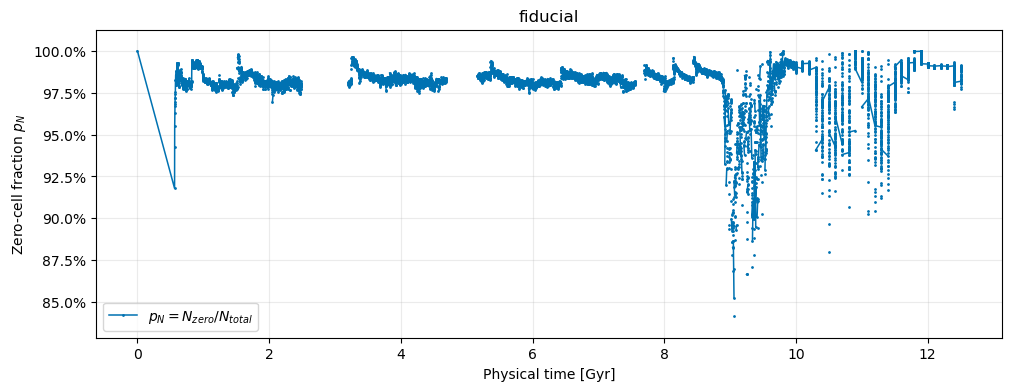

C:\Users\augus\AppData\Local\Temp\ipykernel_40700\2234381276.py:29: UserWarning: fiducial_4 的 HDF 时间存在重复或倒退，已断线；请核对运行/重启身份。
  warnings.warn(f'{key} 的 HDF 时间存在重复或倒退，已断线；请核对运行/重启身份。')


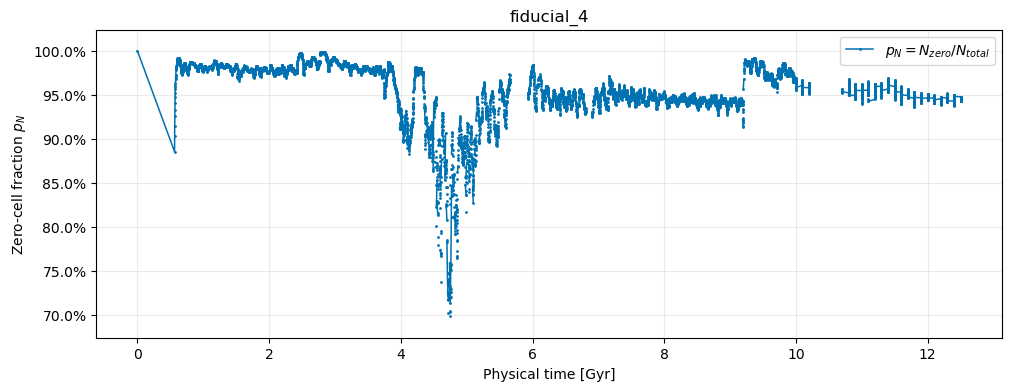

C:\Users\augus\AppData\Local\Temp\ipykernel_40700\2234381276.py:29: UserWarning: fiducial_7 的 HDF 时间存在重复或倒退，已断线；请核对运行/重启身份。
  warnings.warn(f'{key} 的 HDF 时间存在重复或倒退，已断线；请核对运行/重启身份。')


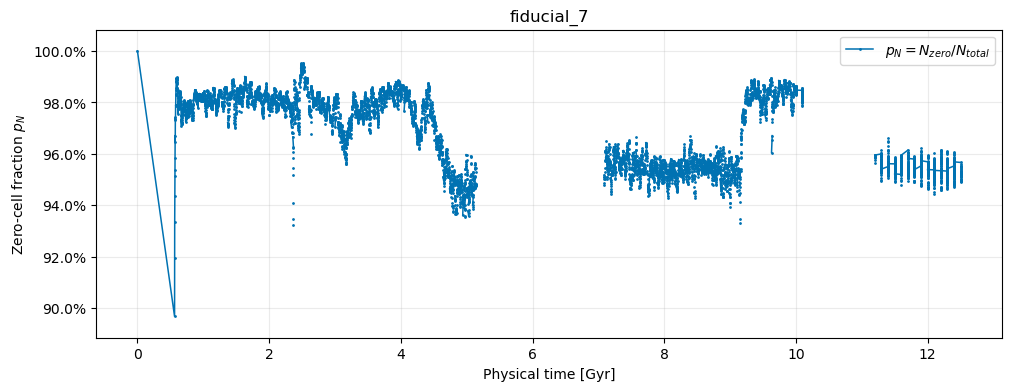

C:\Users\augus\AppData\Local\Temp\ipykernel_40700\2234381276.py:29: UserWarning: model_0_75 的 HDF 时间存在重复或倒退，已断线；请核对运行/重启身份。
  warnings.warn(f'{key} 的 HDF 时间存在重复或倒退，已断线；请核对运行/重启身份。')


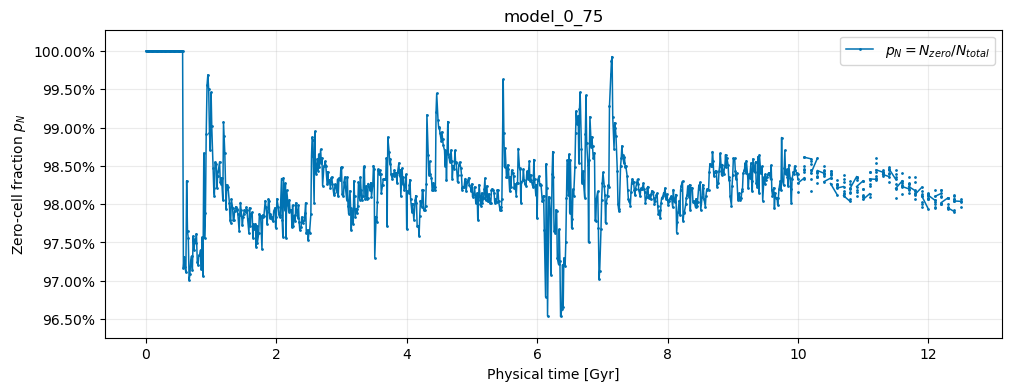

C:\Users\augus\AppData\Local\Temp\ipykernel_40700\2234381276.py:29: UserWarning: model_1_1 的 HDF 时间存在重复或倒退，已断线；请核对运行/重启身份。
  warnings.warn(f'{key} 的 HDF 时间存在重复或倒退，已断线；请核对运行/重启身份。')


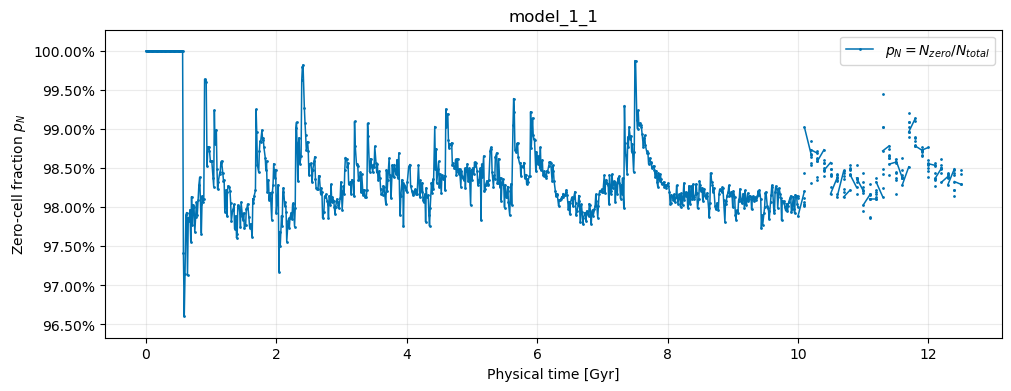

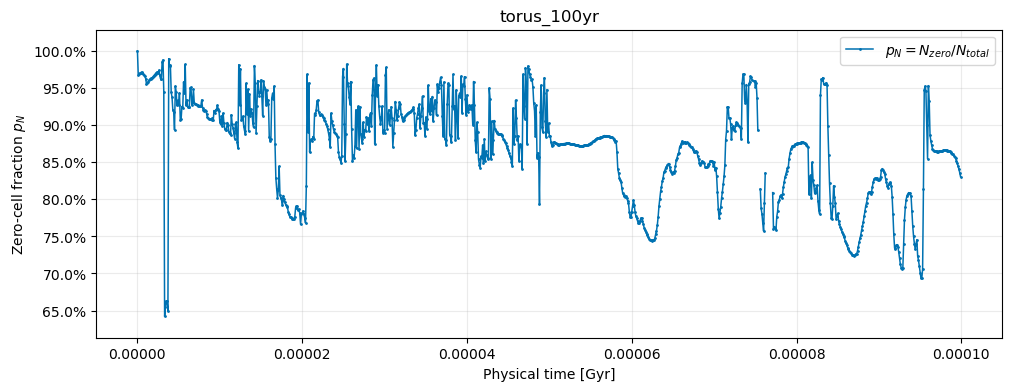

fiducial_10：没有可用的时间曲线。


In [9]:
# 时间曲线绘图 cell：不重新读取原始 snapshot。
def plot_zero_evolution(stats, keys, time_unit='Gyr'):
    scale = {'Gyr': 1.0, 'Myr': 1.0e3, 'yr': 1.0e9}[time_unit]
    figures = {}
    for key in keys:
        rows = stats.loc[stats['galaxy'].eq(key)].sort_values('snapshot_index')
        if rows.empty or not rows['p_N'].notna().any():
            print(f'{key}：没有可用的时间曲线。')
            continue
        fig, ax = plt.subplots(figsize=(10, 3.8), constrained_layout=True)
        x_values, y_values = [], []
        previous_index, previous_time = None, None
        time_reversals = []
        repeated_labels = 0
        for row in rows.itertuples(index=False):
            if not np.isfinite(row.time_gyr) or not np.isfinite(row.p_N):
                x_values.append(np.nan)
                y_values.append(np.nan)
                previous_index, previous_time = None, None
                continue
            if previous_index is not None:
                if row.snapshot_index != previous_index + 1 or row.time_gyr < previous_time:
                    x_values.append(np.nan)
                    y_values.append(np.nan)
                # 相等的标签可能来自科学计数法的有限打印精度，不等于重复 snapshot。
                if row.time_gyr < previous_time:
                    time_reversals.append((previous_index, row.snapshot_index, previous_time, row.time_gyr))
                elif row.time_gyr == previous_time:
                    repeated_labels += 1
            x_values.append(row.time_gyr * scale)
            y_values.append(row.p_N)
            previous_index, previous_time = row.snapshot_index, row.time_gyr
        if repeated_labels:
            print(f'{key}：{repeated_labels} 对相邻可读帧共享 HDF 时间标签（可能由打印精度造成）；'
                  '保留全部帧，不因标签相等断线。')
        if time_reversals:
            warnings.warn(f'{key} 的 HDF 时间标签有 {len(time_reversals)} 处严格倒退，已断线；'
                          f'请核对运行/重启身份。示例 (前编号, 后编号, 前时间, 后时间)：{time_reversals[:3]}')
        ax.plot(x_values, y_values, color='#0072B2', linewidth=1.1,
                marker='.', markersize=2, label=r'$p_N=N_{zero}/N_{total}$')
        abnormal = rows.loc[rows['n_abnormal'].gt(0) & rows['p_N'].notna()]
        if not abnormal.empty:
            ax.scatter(abnormal['time_gyr'] * scale, abnormal['p_N'], color='#D55E00',
                       marker='x', s=28, label='Abnormal cells present', zorder=3)
        ax.set(title=key, xlabel=f'Physical time [{time_unit}]', ylabel=r'Zero-cell fraction $p_N$')
        # 按当前星系的实际数据自动缩放纵轴，保留 8% 边距。
        ax.margins(y=0.08)
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1.0))
        ax.grid(alpha=0.25)
        ax.legend(loc='best')
        figures[key] = fig
        plt.show()
    return figures


if 'zero_stats' not in globals():
    raise RuntimeError('请先执行全序列扫描 cell，生成 zero_stats。')
evolution_figures = plot_zero_evolution(zero_stats, SELECTED_GALAXIES, TIME_UNIT)


## 指定单帧零值掩码

修改下方单帧掩码绘图 cell 顶部的 `MASK_SNAPSHOTS` 后，直接重新运行该 cell 即可。
例如 `{'fiducial': 100}` 或 `{'fiducial': [0, 100], 'model_0_75': [45, 999]}`。
此处可以选择未参与全序列扫描的配置运行，不依赖 `zero_stats`。

横轴为 $\log_{10}(r/\mathrm{kpc})$，纵轴为极角 $\theta$（度），数据保持 `(N_theta,N_r)` 顺序。
**蓝色：SFR=0；橙色：有限 SFR>0；紫红色：NaN/Inf/负 SFR。**
绘图边界由真实坐标中心在图示坐标中取中点构造，仅用于显示，不用于体积计算。
坏帧、缺帧或语义/坐标错误会报告而不绘图。


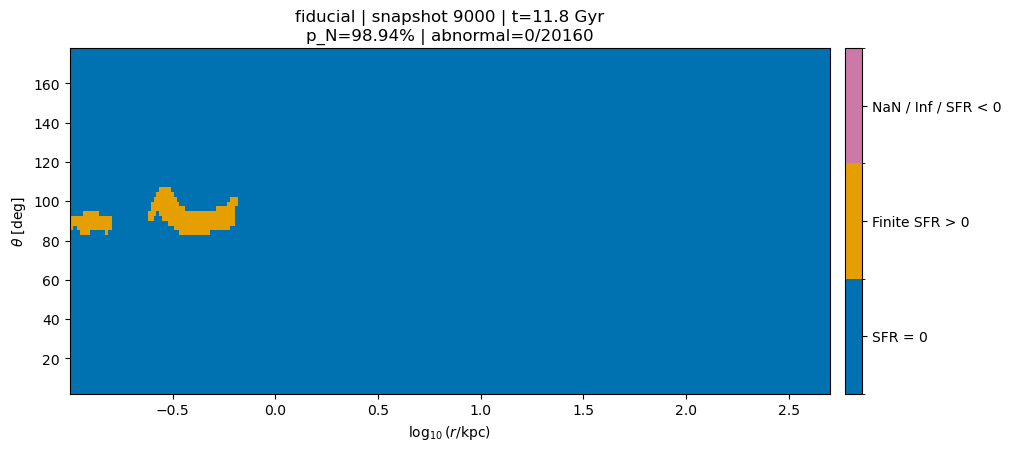

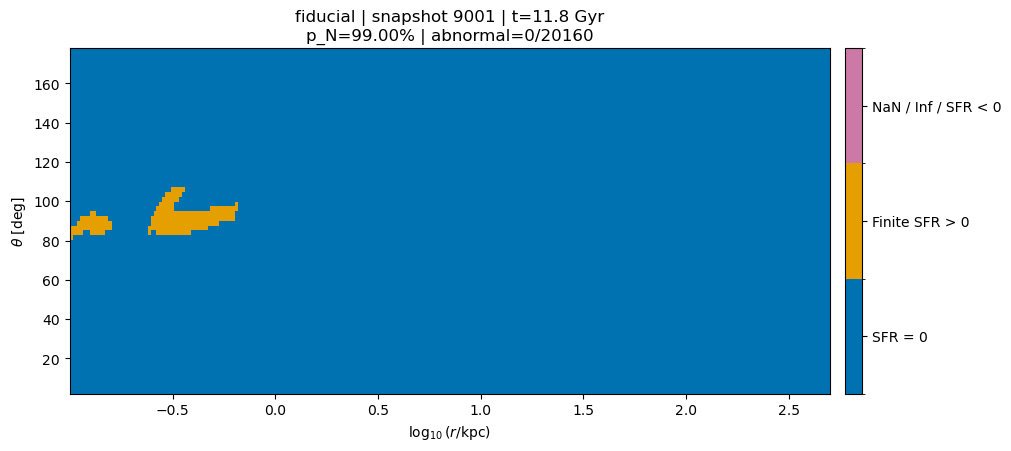

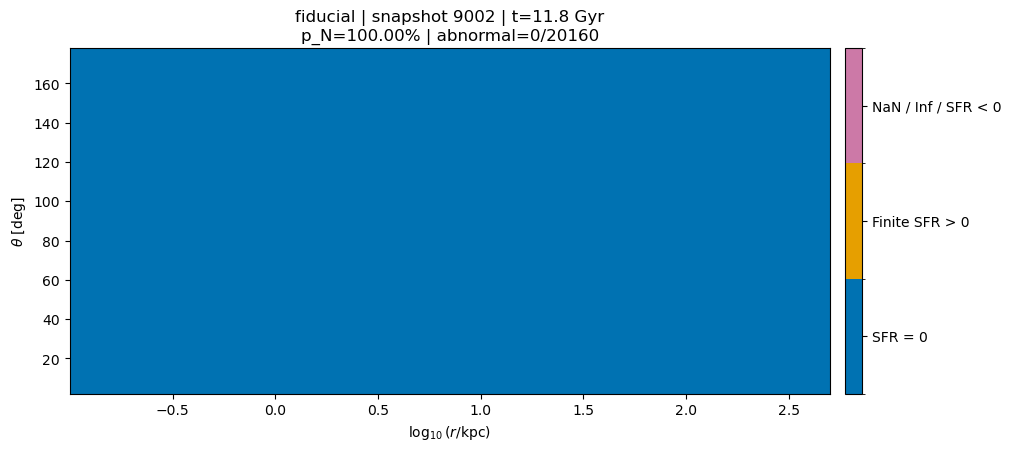

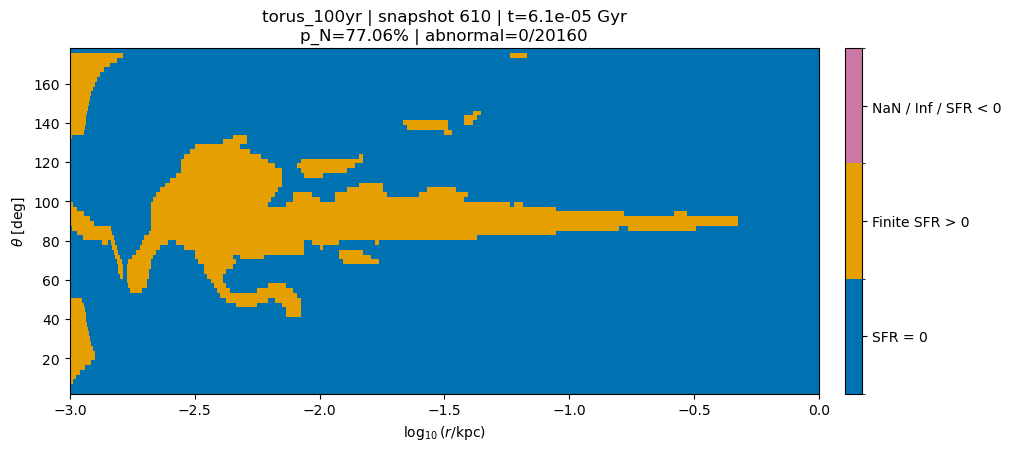

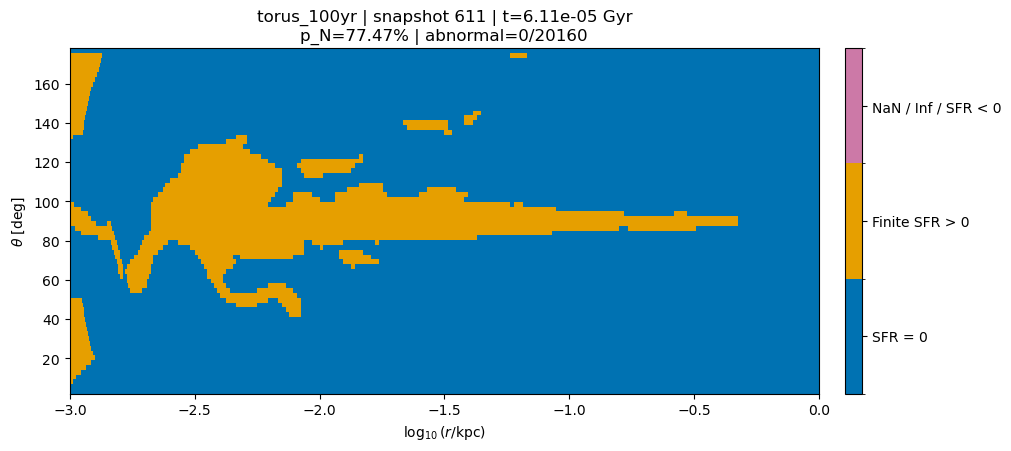

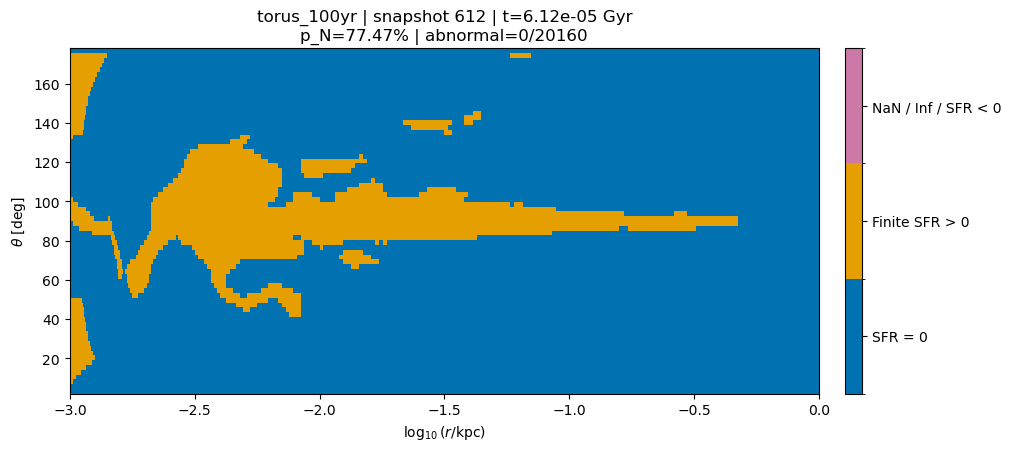

,galaxy,snapshot_index,error,n_total,n_zero,n_nonzero,n_abnormal,p_N,p_abnormal,time_gyr,file,status
0,fiducial,9000,,20160,19946,214,0,0.989385,0.0,11.800000,E:\科研项目与原始数据\ai+MACERsimulation\MACNet-v1\RawD...,ok
1,fiducial,9001,,20160,19959,201,0,0.990030,0.0,11.800000,E:\科研项目与原始数据\ai+MACERsimulation\MACNet-v1\RawD...,ok
2,fiducial,9002,,20160,20160,0,0,1.000000,0.0,11.800000,E:\科研项目与原始数据\ai+MACERsimulation\MACNet-v1\RawD...,ok
3,torus_100yr,610,,20160,15536,4624,0,0.770635,0.0,0.000061,E:\科研项目与原始数据\ai+MACERsimulation\MACNet-v1\RawD...,ok
4,torus_100yr,611,,20160,15618,4542,0,0.774702,0.0,0.000061,E:\科研项目与原始数据\ai+MACERsimulation\MACNet-v1\RawD...,ok
5,torus_100yr,612,,20160,15617,4543,0,0.774653,0.0,0.000061,E:\科研项目与原始数据\ai+MACERsimulation\MACNet-v1\RawD...,ok


In [19]:
# 单帧掩码绘图 cell：独立读取所选 snapshot，无需执行全序列扫描。
# 单帧绘图独立于 GALAXIES 和全序列扫描；编号取文件名后缀，不是文件排序位置。
# 单个编号和多个编号均可；空字典表示不画单帧。
MASK_SNAPSHOTS = {'fiducial': [9000,9001,9002],'torus_100yr':[610,611,612]}
# MASK_SNAPSHOTS = {'fiducial': [0, 100, 999], 'model_0_75': 45}

def display_edges(centers):
    centers = np.asarray(centers, dtype=np.float64)
    edges = np.empty(centers.size + 1)
    edges[1:-1] = (centers[:-1] + centers[1:]) / 2
    edges[0] = centers[0] - (centers[1] - centers[0]) / 2
    edges[-1] = centers[-1] + (centers[-1] - centers[-2]) / 2
    return edges


def plot_sfr_mask(frame, key, index, time_unit='Gyr'):
    categories = classify_sfr(frame['sfr'])
    summary = summarize_sfr(frame['sfr'])
    colors = ListedColormap(['#0072B2', '#E69F00', '#CC79A7'])
    norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5], colors.N)
    log_r_edges = display_edges(np.log10(frame['r']))
    theta_edges = np.clip(display_edges(np.rad2deg(frame['theta'])), 0, 180)
    fig, ax = plt.subplots(figsize=(10, 4.4), constrained_layout=True)
    mesh = ax.pcolormesh(log_r_edges, theta_edges, categories, cmap=colors, norm=norm,
                         shading='flat', rasterized=True)
    scale = {'Gyr': 1.0, 'Myr': 1.0e3, 'yr': 1.0e9}[time_unit]
    ax.set(xlabel=r'$\log_{10}(r/\mathrm{kpc})$', ylabel=r'$\theta$ [deg]',
           title=f'{key} | snapshot {index} | t={frame["time_gyr"] * scale:.8g} {time_unit}\n'
                 f'p_N={summary["p_N"]:.2%} | abnormal={summary["n_abnormal"]}/{summary["n_total"]}')
    colorbar = fig.colorbar(mesh, ax=ax, ticks=[0, 1, 2], pad=0.02)
    colorbar.ax.set_yticklabels(['SFR = 0', 'Finite SFR > 0', 'NaN / Inf / SFR < 0'])
    plt.show()
    return fig


def plot_selected_masks(selection, time_unit='Gyr'):
    figures, records = {}, []
    for name, values in selection.items():
        key = galaxy_key(name)
        indices = integer_indices(values)
        try:
            indexed = discover_snapshots(key)
        except (OSError, ValueError) as exc:
            print(f'{key}：{exc}')
            records.extend({'galaxy': key, 'snapshot_index': index, 'status': 'unavailable', 'error': str(exc)}
                           for index in indices)
            continue
        for index in indices:
            row = {'galaxy': key, 'snapshot_index': index, 'error': ''}
            if index in EXCLUDED[key]:
                row.update(status='excluded', error='排除清单；未读取')
            elif index not in indexed:
                row.update(status='missing', error='没有对应文件编号')
            else:
                try:
                    frame = read_sfr_snapshot(indexed[index])
                    summary = summarize_sfr(frame['sfr'])
                    figures[(key, index)] = plot_sfr_mask(frame, key, index, time_unit)
                    row.update(summary)
                    row.update(time_gyr=frame['time_gyr'], file=str(indexed[index]),
                               status='abnormal' if summary['n_abnormal'] else 'ok')
                except (OSError, ValueError, KeyError, RuntimeError, HDF4Error) as exc:
                    row.update(status='read_error', error=f'{type(exc).__name__}: {exc}')
            if row['error']:
                print(f'{key} / {index}：{row["error"]}')
            records.append(row)
    return figures, pd.DataFrame(records)


mask_figures, mask_summary = plot_selected_masks(MASK_SNAPSHOTS, TIME_UNIT)
if not mask_summary.empty:
    display(mask_summary)
else:
    print('MASK_SNAPSHOTS 为空，没有指定单帧。')
